# 01 訓練流程：新竹站下一小時 PM2.5 的線性迴歸（作業 §5–§7）

用過去 9 小時（lag 1–9h）的 18 個測項，預測新竹測站下一小時的 PM2.5（μg/m³）。

| 步驟 | 內容 | 對應論文段落 |
|---|---|---|
| 1 | 設定、決策門檻 | §6.2 |
| 2 | 讀檔、hybrid 資料檢查 | §3.2 |
| 3 | TimeSeriesSplit folds | §6.1 |
| 4 | 特徵組與共線性（VIF） | §5.1、§5.2 |
| 5 | Baseline（由弱到強） | §6.2 |
| 6 | 線性模型選擇與調參 | §5.2 |
| 7 | 主要結果（CV） | §7.1 |
| 8 | Ablation：Set A / B / C、逐群移除 | §7.2 |
| 9 | 穩健性檢查：fold 內標準化 | §9 限制 |
| 10 | Pipeline 圖 | §5.1 |
| 11 | **Test 只評估一次** | §7.1 |

**資料（hybrid）**：目標用 `pure_all.csv`（原始單位），原始欄位用 `standardized_all.csv` 的 z-score，
衍生特徵從 `pure_all.csv` 計算後在 Pipeline 內 fold 內標準化。細節見 `features.py` 開頭說明。

執行完再接著跑 `02_analysis.ipynb`。所有輸出寫到 `Model/figures/`、`Model/tables/`、`Model/outputs/`。

## 1. 設定

### 評估指標（§6.2）

| 指標 | 單位 | 為什麼用 |
|---|---|---|
| **MAE**（主要指標） | μg/m³ | 平均差幾 μg/m³，最直觀；所有誤差線性加權，不會被少數極端值主導。CV 選模型、決策門檻都用 MAE |
| RMSE | μg/m³ | 對大誤差加重，反映濃度突變、高濃度時段的錯誤；和 MAE 的差距代表誤差分布的尾部有多重 |
| R² | 無 | 解釋了多少變異，可以跨 fold、跨季節比較；但 test 期間的濃度變異較小，R² 要搭配 MAE 一起看，也可能為負 |

不使用 MAPE：目標有 0 值（train 160 筆、test 69 筆），除以實際值會不穩定（p.13）。

### 決策門檻：MAE ≤ 3 μg/m³

- 應用情境：直接使用**小時濃度**。例如敏感族群看下一小時的 PM2.5 預測值，決定要不要外出或調整戶外活動。
- 尺度依據：用環境部自 2025-01-01 起的 AQI 分級當作「有意義的濃度誤差尺度」：PM2.5「良好」為 0–12.4、「普通」為 12.5–30.4、「對敏感族群不健康」為 30.5–50.4 μg/m³。「普通」級寬 18 μg/m³，平均誤差 3 μg/m³ 約為級寬的六分之一。
- 限制：分級本身不是針對單一小時濃度。日 AQI 的分級用 24 小時平均值定義；即時 AQI 的 PM2.5 濃度是 0.5 × 前 12 小時平均 + 0.5 × 前 4 小時平均。所以不能把門檻寫成「MAE ≤ 3 就代表 AQI 等級判斷正確」。
- 換算到即時 AQI，門檻是保守的：t 時刻兩個窗口裡只有 t 這一小時是預測值，每小時誤差 e 傳到即時 AQI 濃度只剩 0.5 × e/12 + 0.5 × e/4 = e/6，3 μg/m³ 換算後約 0.5 μg/m³。test 上的驗證在 `02_analysis.ipynb` 第 6 步。
- 已知結果：persistence 也達到這個門檻（CV MAE 2.91、test MAE 2.55）。門檻代表的是「可用」的誤差水準；模型的價值要看它和 baseline 的比較（§7），而不是看有沒有過門檻。門檻的數值沒有因為看過結果而調整。

需要時可以修改 `THRESHOLD_MAE`。

In [1]:
import json
import sys
import warnings
from pathlib import Path

# 讓 notebook 不論從 repo 根目錄或 Model/ 開啟都找得到 features.py
MODEL_DIR = Path.cwd() if (Path.cwd() / "features.py").exists() else Path.cwd() / "Model"
sys.path.insert(0, str(MODEL_DIR))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

import features as F

F.setup_plotting()
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", 50, "display.width", 160)

from matplotlib.patches import FancyBboxPatch
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

THRESHOLD_MAE = 3.0  # μg/m³
SCORING = "neg_mean_absolute_error"

## 2. 讀檔與 hybrid 資料檢查

`load_hybrid()` 會 assert 兩檔的時間與 train/test 標記逐列一致。下面再檢查兩件事：
1. standardized 檔是 pure 的仿射轉換（兩者相關係數 = 1）。
2. 標準化只用 train：train 期間的 z 平均為 0。

In [2]:
data = F.load_hybrid()
X = F.build_frame(data)
y = data.y
train_mask, test_mask = data.is_train, ~data.is_train
# train 在前、test 在後（依時間切分）
assert train_mask[: train_mask.sum()].all() and not train_mask[train_mask.sum():].any()

X_train, y_train = X[train_mask].reset_index(drop=True), y[train_mask].reset_index(drop=True)
X_test, y_test = X[test_mask].reset_index(drop=True), y[test_mask].reset_index(drop=True)
time_train = data.time[train_mask].reset_index(drop=True)
time_test = data.time[test_mask].reset_index(drop=True)
assert (len(X_train), len(X_test)) == (6930, 1733)

raw, z = data.R["PM2.5_lag_1h"], data.Z["PM2.5_lag_1h"]
observed = raw.notna()
assert np.corrcoef(raw[observed], z[observed])[0, 1] > 1 - 1e-6, "standardized 不是 pure 的仿射轉換"
assert abs(data.Z.loc[train_mask, "PM2.5_lag_1h"].mean()) < 1e-6, "標準化不是只用 train"

overview = pd.DataFrame({
    "split": ["train", "test"],
    "start": [time_train.min(), time_test.min()],
    "end": [time_train.max(), time_test.max()],
    "rows": [len(y_train), len(y_test)],
    "target_mean (μg/m³)": [y_train.mean(), y_test.mean()],
    "target_std (μg/m³)": [y_train.std(ddof=0), y_test.std(ddof=0)],
    "target_max (μg/m³)": [y_train.max(), y_test.max()],
}).round(2)
overview

,split,start,end,rows,target_mean (μg/m³),target_std (μg/m³),target_max (μg/m³)
0,train,2025-01-01 09:00:00,2025-10-19 20:00:00,6930,12.38,8.71,85.0
1,test,2025-10-19 21:00:00,2025-12-31 23:00:00,1733,9.65,6.64,47.0


test 期間（10 月下旬至 12 月）的平均濃度比 train 低，代表 test 和 train 有季節差異。
這也是為什麼不用月份當特徵（train 沒有 11、12 月）。

## 3. 驗證切分：TimeSeriesSplit

- test = 依時間的後 20%，只在第 11 步使用一次。
- train 內用 `TimeSeriesSplit(n_splits=5, gap=9)`：每個驗證 fold 都在其訓練資料之後，不打亂時間順序。
  5 個 fold 每個約 1150 列（約 48 天），每個 fold 都有足夠的天數，也涵蓋不同季節。
  `gap=9` 和 lag 窗口一樣長，驗證列的 9 小時歷史不會和訓練列的目標重疊。
- 所有方法共用同一組索引，存到 `outputs/cv_folds.csv`。

In [3]:
folds = F.make_folds(len(X_train))

fold_table = pd.DataFrame([{
    "fold": k,
    "train_rows": len(tr),
    "train_end": time_train[tr[-1]],
    "val_rows": len(va),
    "val_start": time_train[va[0]],
    "val_end": time_train[va[-1]],
} for k, (tr, va) in enumerate(folds, start=1)])

pd.concat([
    pd.DataFrame({"fold": k, "role": role, "row": idx})
    for k, (tr, va) in enumerate(folds, start=1)
    for role, idx in (("train", tr), ("val", va))
]).to_csv(F.OUT / "cv_folds.csv", index=False)
F.save_table(fold_table, "cv_folds_summary")
fold_table

,fold,train_rows,train_end,val_rows,val_start,val_end
0,1,1146,2025-02-18 11:00:00,1155,2025-02-18 21:00:00,2025-04-08 07:00:00
1,2,2301,2025-04-07 22:00:00,1155,2025-04-08 08:00:00,2025-05-26 20:00:00
2,3,3456,2025-05-26 10:00:00,1155,2025-05-26 21:00:00,2025-07-14 22:00:00
3,4,4611,2025-07-14 13:00:00,1155,2025-07-14 23:00:00,2025-09-01 08:00:00
4,5,5766,2025-08-31 23:00:00,1155,2025-09-01 09:00:00,2025-10-19 20:00:00


## 4. 特徵組與共線性

Set C 依 EDA 的結論分成以下特徵群（定義在 `features.GROUPS`）：

| 特徵群 | 內容 | 依據 |
|---|---|---|
| persistence | PM2.5 lag 1h | EDA r = 0.88 → H1 |
| pm25_aggregates | 趨勢 Δ = lag1 − lag2、3/6/9h 滾動平均、9h 標準差（取代 lag 2–9h） | r 隨 lag 遞減但到 9h 仍有 0.55 → H5 |
| co_pollutants | PM10、CO lag 1–3h；NO、NO2、O3、SO2、CH4、NMHC lag 1h | PM10 r = 0.78、CO 0.60 → H2 |
| meteorology | 溫度、濕度、雨量 lag 1h、有雨旗標 | 溫度 r ≈ −0.33（季節） → H4 |
| wind | 風速、風向 sin/cos、風向量 u/v | 角度必須轉換 |
| wind_bins | 風速 < 1、≥ 6 m/s 旗標（基準 1–6） | Fig 4 非線性 → H3 |
| interaction | PM2.5(t−1) × 風速(t−1) | 風大時持續性應下降 → H3 |
| calendar | 目標小時 sin/cos、週末 | 小時差異小，週末可能有交通差異 |
| missing_flag | PM2.5 lag 1h 是否為補值 | standardized 檔用平均數補值 |

刪除共線欄位（刪除前的 VIF 來自 `EDA/tables/vif.csv`：18 個測項 @ lag 1h，n = 6402；刪除後的 VIF 見下面的 Set C 表）：

- **完全共線**：NOx = NO + NO2、THC = CH4 + NMHC。刪除前 VIF 為 NOx 19,367、NO2 11,950、NO 2,718；THC 13,707、CH4 7,671、NMHC 1,765。刪掉加總欄 NOx、THC，保留可以分開解讀的成分。刪除後 Set C 中 NO 1.98、NO2 4.76、CH4 2.89、NMHC 4.71。
- **重複量測**：WS_HR、WD_HR。VIF 不高（WS_HR 8.69，WD_HR sin/cos 5.73、5.39），但和 WIND_SPEED 的 r = 0.94、和 WIND_DIREC sin/cos 的 r ≈ 0.9（EDA Fig 5），內容幾乎相同，擇一保留 WIND_SPEED、WIND_DIREC。

下面在 train 上計算 Set C 的 VIF，作為選擇線性模型變體的依據（§5.2）。

In [4]:
prep_c = F.make_preprocessor(F.SET_C).fit(X_train)
X_train_c = pd.DataFrame(prep_c.transform(X_train), columns=prep_c.get_feature_names_out())
vif_c = F.vif(X_train_c).sort_values(ascending=False).rename("VIF")
F.save_table(vif_c.round(2).rename_axis("feature").reset_index(), "vif_set_c")

group_of = {c: g for g, cols in F.GROUPS.items() for c in cols}
print(f"Set C：{len(F.SET_C)} 個特徵；VIF ≥ 10 的有 {(vif_c >= 10).sum()} 個")
vif_c.to_frame().assign(group=lambda d: d.index.map(group_of)).head(15).round(1)

Set C：34 個特徵；VIF ≥ 10 的有 7 個


,VIF,group
eng_pm25_mean3h,66.4,pm25_aggregates
eng_pm25_mean6h,60.6,pm25_aggregates
z_PM2.5_lag_1h,43.7,persistence
eng_pm25_mean9h,28.3,pm25_aggregates
z_PM10_lag_2h,14.2,co_pollutants
z_CO_lag_2h,11.8,co_pollutants
z_PM10_lag_3h,10.1,co_pollutants
z_CO_lag_1h,10.0,co_pollutants
z_PM10_lag_1h,9.8,co_pollutants
eng_wind_v,8.2,wind


## 5. Baseline（由弱到強）

| Baseline | 說明 |
|---|---|
| Training mean | 永遠預測 train 平均 |
| Persistence (t−1) | 預測值 = 上一小時的 PM2.5（缺值時往前找 lag2、lag3） |
| Single-feature OLS | 只用 PM2.5(t−1) 的 OLS |
| HistGradientBoosting (raw) | 強 baseline：非線性模型，用 162 個原始欄位（原始單位、保留缺值） |

In [5]:
BASELINES = {
    "Training mean": DummyRegressor(strategy="mean"),
    "Persistence (t-1)": F.Persistence(),
    "Single-feature OLS (PM2.5 t-1)": F.linear_pipeline(["z_PM2.5_lag_1h"], LinearRegression()),
    "HistGradientBoosting (raw)": Pipeline([
        ("prep", ColumnTransformer([("raw", "passthrough", F.RAW_ALL)])),
        ("model", HistGradientBoostingRegressor(random_state=F.SEED)),
    ]),
}

per_fold = []


def record(method, kind, estimator):
    scores = F.cv_scores(estimator, X_train, y_train, folds)
    scores.insert(0, "method", method)
    scores.insert(1, "kind", kind)
    per_fold.append(scores)
    return scores


for name, estimator in BASELINES.items():
    record(name, "baseline", estimator)

F.summarize(pd.concat(per_fold)).round(3)

,method,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std
0,Training mean,7.360,1.438,8.861,1.650,-1.194,1.698
1,Persistence (t-1),2.912,0.401,4.022,0.558,0.601,0.164
2,Single-feature OLS (PM2.5 t-1),2.994,0.322,3.964,0.547,0.611,0.164
3,HistGradientBoosting (raw),3.021,0.631,4.012,0.975,0.634,0.102


## 6. 線性模型選擇與調參（Set C，只用 train 的 CV）

| 變體 | 搜尋範圍 |
|---|---|
| OLS | 無超參數 |
| Ridge | α ∈ 10^[−3, 3]，13 個 log 等距值 |
| Lasso | α ∈ 10^[−4, 0]，13 個 log 等距值 |
| ElasticNet | α 同 Lasso；l1_ratio ∈ {0.1, 0.5, 0.9} |

以 CV MAE 最低者為最終模型。若 VIF 顯示 Set C 有明顯共線（第 4 步），預期 Ridge 會勝出或和 OLS 打平，
因為 Ridge 保留所有特徵、只收縮不穩定的係數。

In [6]:
ALPHAS_RIDGE = np.logspace(-3, 3, 13)
ALPHAS_L1 = np.logspace(-4, 0, 13)
CANDIDATES = {
    "OLS": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": ALPHAS_RIDGE}),
    "Lasso": (Lasso(max_iter=50_000), {"model__alpha": ALPHAS_L1}),
    "ElasticNet": (ElasticNet(max_iter=50_000), {"model__alpha": ALPHAS_L1, "model__l1_ratio": [0.1, 0.5, 0.9]}),
}
SEARCH_RANGE = {
    "OLS": "none",
    "Ridge": "alpha: 13 log-spaced values in [1e-3, 1e3]",
    "Lasso": "alpha: 13 log-spaced values in [1e-4, 1]",
    "ElasticNet": "alpha: 13 log-spaced values in [1e-4, 1]; l1_ratio in {0.1, 0.5, 0.9}",
}

searches = {}
for name, (model, grid) in CANDIDATES.items():
    search = GridSearchCV(F.linear_pipeline(F.SET_C, model), grid, cv=folds, scoring=SCORING, n_jobs=-1)
    searches[name] = search.fit(X_train, y_train)
    record(f"{name} + Set C", "linear", search.best_estimator_)

selection = pd.DataFrame([{
    "model": name,
    "search_range": SEARCH_RANGE[name],
    "selected": {k.replace("model__", ""): float(v) for k, v in s.best_params_.items()} or "-",
    "cv_mae_mean": -s.best_score_,
    "cv_mae_std": s.cv_results_["std_test_score"][s.best_index_],
} for name, s in searches.items()])
F.save_table(selection.round(4), "model_selection")

FINAL_NAME = selection.loc[selection["cv_mae_mean"].idxmin(), "model"]
FINAL_METHOD = f"{FINAL_NAME} + Set C"
FINAL_MODEL, FINAL_GRID = CANDIDATES[FINAL_NAME]
print("最終模型：", FINAL_METHOD, searches[FINAL_NAME].best_params_)
selection.round(4)

最終模型： Ridge + Set C {'model__alpha': np.float64(31.622776601683793)}


,model,search_range,selected,cv_mae_mean,cv_mae_std
0,OLS,none,-,2.7770,0.4578
1,Ridge,"alpha: 13 log-spaced values in [1e-3, 1e3]",{'alpha': 31.622776601683793},2.7513,0.4178
2,Lasso,"alpha: 13 log-spaced values in [1e-4, 1]",{'alpha': 0.021544346900318822},2.7557,0.4162
3,ElasticNet,"alpha: 13 log-spaced values in [1e-4, 1]; l1_r...","{'alpha': 0.021544346900318822, 'l1_ratio': 0.5}",2.7520,0.4195


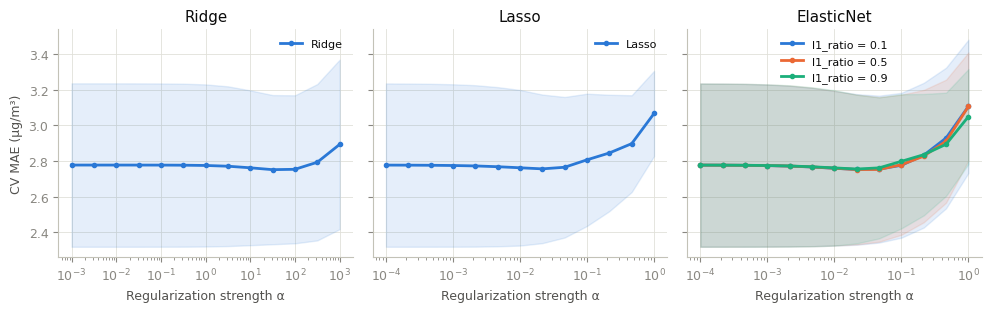

In [7]:
# 調參曲線：CV MAE（mean ± std）對 α
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, name in zip(axes, ["Ridge", "Lasso", "ElasticNet"]):
    res = pd.DataFrame(searches[name].cv_results_)
    ratios = res["param_model__l1_ratio"].unique() if name == "ElasticNet" else [None]
    for color, ratio in zip(F.SERIES, ratios):
        part = res if ratio is None else res[res["param_model__l1_ratio"] == ratio]
        alpha = part["param_model__alpha"].astype(float)
        mae, std = -part["mean_test_score"], part["std_test_score"]
        label = name if ratio is None else f"l1_ratio = {ratio}"
        ax.plot(alpha, mae, color=color, marker="o", markersize=3, label=label)
        ax.fill_between(alpha, mae - std, mae + std, color=color, alpha=0.12)
    ax.set_xscale("log")
    ax.set_xlabel("Regularization strength α")
    ax.set_title(name)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("CV MAE (μg/m³)")
F.save_fig(fig, "fig1_tuning_curves")
plt.show()

## 7. 主要結果（CV，mean ± std over 5 folds）

In [8]:
cv_main = F.summarize(pd.concat(per_fold))
cv_main.round(3)

,method,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std
0,Training mean,7.360,1.438,8.861,1.650,-1.194,1.698
1,Persistence (t-1),2.912,0.401,4.022,0.558,0.601,0.164
2,Single-feature OLS (PM2.5 t-1),2.994,0.322,3.964,0.547,0.611,0.164
3,HistGradientBoosting (raw),3.021,0.631,4.012,0.975,0.634,0.102
4,OLS + Set C,2.777,0.512,3.818,0.883,0.664,0.100
5,Ridge + Set C,2.751,0.467,3.768,0.792,0.669,0.104
6,Lasso + Set C,2.756,0.465,3.772,0.805,0.669,0.103
7,ElasticNet + Set C,2.752,0.469,3.768,0.803,0.670,0.103


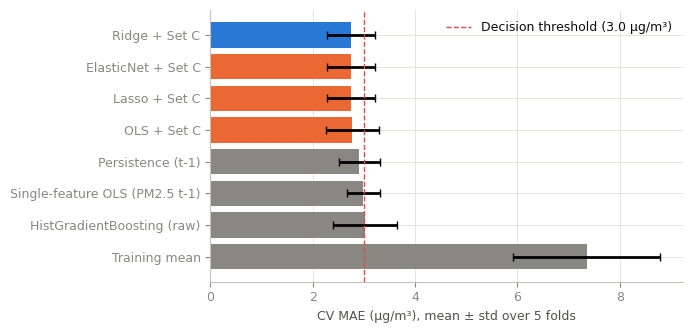

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.4))
order = cv_main.sort_values("cv_mae_mean", ascending=True)
colors = [F.BLUE if m == FINAL_METHOD else (F.ORANGE if "Set C" in m else F.MUTED) for m in order["method"]]
ax.barh(order["method"], order["cv_mae_mean"], xerr=order["cv_mae_std"], color=colors, capsize=3)
ax.axvline(THRESHOLD_MAE, color=F.RED, linestyle="--", linewidth=1, label=f"Decision threshold ({THRESHOLD_MAE} μg/m³)")
ax.invert_yaxis()
ax.set_xlabel("CV MAE (μg/m³), mean ± std over 5 folds")
ax.legend(frameon=False, loc="upper right")
F.save_fig(fig, "fig2_cv_comparison")
plt.show()

## 8. Ablation：只換特徵組

同一個最終模型、同樣的 folds、同樣的調參網格，只改變特徵：

- **Set A**：全部 162 個原始欄位（standardized）。
- **Set B**：從 Set A 中取 |Spearman ρ| 最高的 k 個。**在每個訓練 fold 內**重新排序（`TopKSpearman`），
  k ∈ {5, 10, 20} 和 α 一起用 CV 選。
- **Set C**：我們的特徵組。
- **H5 對照**：Set C 但 PM2.5 聚合特徵換回 lag 1–9h 原始欄位。
- **逐群移除**：從 Set C 一次拿掉一個特徵群。

In [10]:
ABLATIONS = {
    "Set A: all 162 raw columns": (F.SET_A, False),
    "Set B: top-k |Spearman| (in-fold)": (F.SET_A, True),
    "Set C: ours": (F.SET_C, False),
    "Set C with PM2.5 lags 1-9h instead of aggregates": (F.set_c_with_raw_lags(), False),
    **{f"Set C - {group}": (F.set_c_without(group), False) for group in F.GROUPS},
}

ablation_searches = {}
for name, (columns, topk) in ABLATIONS.items():
    grid = dict(FINAL_GRID)
    if topk:
        grid["select__k"] = [5, 10, 20]
    builder = F.topk_pipeline if topk else F.linear_pipeline
    search = GridSearchCV(builder(columns, clone(FINAL_MODEL)), grid, cv=folds, scoring=SCORING, n_jobs=-1)
    ablation_searches[name] = search.fit(X_train, y_train)
    record(name, "ablation", search.best_estimator_)

ablation = F.summarize(pd.concat(per_fold).query("kind == 'ablation'"))
reference = ablation.set_index("method").loc["Set C: ours", "cv_mae_mean"]
# Set B 實際使用的是選出的 k 個特徵，不是候選的 162 個
ablation["n_features"] = [
    ablation_searches[m].best_params_.get("select__k", len(ABLATIONS[m][0])) for m in ablation["method"]
]
ablation["selected_params"] = [str(ablation_searches[m].best_params_) for m in ablation["method"]]
ablation["delta_mae_vs_C"] = ablation["cv_mae_mean"] - reference
F.save_table(ablation.round(4), "ablation")
ablation.round(3)

,method,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std,n_features,selected_params,delta_mae_vs_C
0,Set A: all 162 raw columns,2.871,0.555,3.913,0.949,0.651,0.096,162,{'model__alpha': np.float64(100.0)},0.119
1,Set B: top-k |Spearman| (in-fold),2.754,0.398,3.752,0.767,0.670,0.109,20,{'model__alpha': np.float64(31.622776601683793...,0.003
2,Set C: ours,2.751,0.467,3.768,0.792,0.669,0.104,34,{'model__alpha': np.float64(31.622776601683793)},0.000
3,Set C with PM2.5 lags 1-9h instead of aggregates,2.757,0.477,3.777,0.802,0.668,0.104,37,{'model__alpha': np.float64(31.622776601683793)},0.006
4,Set C - persistence,2.787,0.490,3.815,0.838,0.664,0.100,33,{'model__alpha': np.float64(31.622776601683793)},0.035
5,Set C - pm25_aggregates,2.816,0.489,3.860,0.809,0.654,0.107,29,{'model__alpha': np.float64(31.622776601683793)},0.064
6,Set C - co_pollutants,2.912,0.388,3.888,0.583,0.633,0.141,22,{'model__alpha': np.float64(10.0)},0.161
7,Set C - meteorology,2.778,0.441,3.779,0.756,0.665,0.110,30,{'model__alpha': np.float64(31.622776601683793)},0.026
8,Set C - wind,2.742,0.448,3.758,0.781,0.670,0.105,29,{'model__alpha': np.float64(31.622776601683793)},-0.009
9,Set C - wind_bins,2.755,0.472,3.771,0.803,0.670,0.103,32,{'model__alpha': np.float64(31.622776601683793)},0.004


In [11]:
# Set B 在全部 train 上選出的特徵（報告用；CV 中每個 fold 各自重選）
best_b = ablation_searches["Set B: top-k |Spearman| (in-fold)"].best_estimator_
names_b = best_b.named_steps["prep"].get_feature_names_out()[best_b.named_steps["select"].support_]
F.save_table(pd.DataFrame({"feature": names_b}), "setB_selected_features")
print(f"k = {len(names_b)}：", list(names_b))

k = 20： ['z_CO_lag_1h', 'z_PM10_lag_1h', 'z_PM2.5_lag_1h', 'z_CO_lag_2h', 'z_PM10_lag_2h', 'z_PM2.5_lag_2h', 'z_CO_lag_3h', 'z_PM10_lag_3h', 'z_PM2.5_lag_3h', 'z_PM10_lag_4h', 'z_PM2.5_lag_4h', 'z_PM10_lag_5h', 'z_PM2.5_lag_5h', 'z_PM10_lag_6h', 'z_PM2.5_lag_6h', 'z_PM10_lag_7h', 'z_PM2.5_lag_7h', 'z_PM10_lag_8h', 'z_PM2.5_lag_8h', 'z_PM2.5_lag_9h']


## 9. 穩健性檢查：fold 內標準化

standardized 檔的平均數與標準差是用整個 train 期間計算的，所以 CV 的驗證 fold 也參與了這些統計量的估計（不影響 test）。
這裡把 Set C 的 `z_` 欄全部換成 pure 原始值，在每個 fold 內補值與標準化，比較 CV MAE 的差距。
差距若遠小於 fold 間的標準差，就代表這個洩漏可以忽略。

In [12]:
robust_search = GridSearchCV(
    F.linear_pipeline(F.to_raw_units(F.SET_C), clone(FINAL_MODEL)), FINAL_GRID,
    cv=folds, scoring=SCORING, n_jobs=-1,
).fit(X_train, y_train)
robust = record("Set C, scaled in-fold from pure (robustness)", "robustness", robust_search.best_estimator_)

hybrid = pd.concat(per_fold).query("method == @FINAL_METHOD").set_index("fold")["mae"]
robust_compare = pd.DataFrame({"hybrid_mae": hybrid, "in_fold_mae": robust.set_index("fold")["mae"]})
robust_compare["diff"] = robust_compare["in_fold_mae"] - robust_compare["hybrid_mae"]
F.save_table(robust_compare.round(4).reset_index(), "robustness_in_fold_scaling")
print(f"平均差距 {robust_compare['diff'].mean():+.4f} μg/m³；hybrid 的 fold 間標準差 {hybrid.std():.4f}")
robust_compare.round(4)

平均差距 +0.0273 μg/m³；hybrid 的 fold 間標準差 0.4672


,hybrid_mae,in_fold_mae,diff
fold,,,
1,3.4346,3.5614,0.1269
2,3.0091,3.0103,0.0012
3,2.3523,2.3586,0.0063
4,2.3510,2.3505,-0.0004
5,2.6093,2.6122,0.0029


## 10. Pipeline 圖（§5.1）

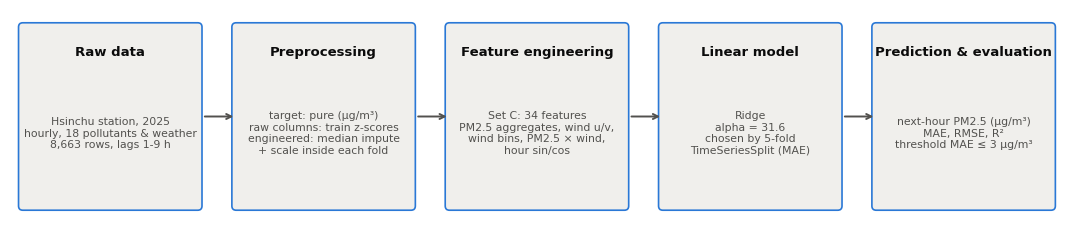

In [13]:
best = searches[FINAL_NAME].best_params_
param_text = ", ".join(f"{k.replace('model__', '')} = {v:.3g}" for k, v in best.items()) or "no hyperparameter"
stages = [
    ("Raw data", "Hsinchu station, 2025\nhourly, 18 pollutants & weather\n8,663 rows, lags 1-9 h"),
    ("Preprocessing", "target: pure (μg/m³)\nraw columns: train z-scores\nengineered: median impute\n+ scale inside each fold"),
    ("Feature engineering", f"Set C: {len(F.SET_C)} features\nPM2.5 aggregates, wind u/v,\nwind bins, PM2.5 × wind,\nhour sin/cos"),
    ("Linear model", f"{FINAL_NAME}\n{param_text}\nchosen by 5-fold\nTimeSeriesSplit (MAE)"),
    ("Prediction & evaluation", "next-hour PM2.5 (μg/m³)\nMAE, RMSE, R²\nthreshold MAE ≤ 3 μg/m³"),
]
fig, ax = plt.subplots(figsize=(11, 2.4))
ax.set_axis_off()
ax.set_xlim(0, len(stages))
ax.set_ylim(0, 1)
for i, (title, body) in enumerate(stages):
    ax.add_patch(FancyBboxPatch((i + 0.06, 0.08), 0.82, 0.84, boxstyle="round,pad=0.02",
                                facecolor="#f0efec", edgecolor=F.BLUE, linewidth=1.2))
    ax.text(i + 0.47, 0.8, title, ha="center", va="center", fontsize=9.5, fontweight="bold")
    ax.text(i + 0.47, 0.42, body, ha="center", va="center", fontsize=7.8, color=F.INK2)
    if i < len(stages) - 1:
        ax.annotate("", xy=(i + 1.06, 0.5), xytext=(i + 0.9, 0.5),
                    arrowprops=dict(arrowstyle="->", color=F.INK2, lw=1.4))
F.save_fig(fig, "fig0_pipeline")
plt.show()

## 11. Test：只評估一次

所有設計決策（特徵、模型變體、超參數）都已經在上面用 CV 決定。
這裡用全部 train refit（`GridSearchCV` 的 `best_estimator_` 已經 refit 過），在 test 上評估**一次**。

In [14]:
test_models = {name: clone(est).fit(X_train, y_train) for name, est in BASELINES.items()}
test_models.update({f"{name} + Set C": s.best_estimator_ for name, s in searches.items()})
test_models.update({name: ablation_searches[name].best_estimator_ for name in (
    "Set A: all 162 raw columns", "Set B: top-k |Spearman| (in-fold)", "Set C: ours")})

predictions = pd.DataFrame({"target_datetime": time_test, "actual": y_test})
for name, model in test_models.items():
    predictions[name] = model.predict(X_test)

test_scores = pd.DataFrame([
    {"method": name, **{f"test_{k}": v for k, v in F.scores(y_test, predictions[name]).items()}}
    for name in test_models
])
test_scores["meets_threshold"] = test_scores["test_mae"] <= THRESHOLD_MAE

main_results = cv_main.merge(test_scores, on="method", how="outer")
main_results = main_results.set_index("method").loc[[m for m in test_models]].reset_index()
F.save_table(main_results.round(4), "main_results")


def bold_best(column):
    best_value = column.max() if column.name.endswith("r2_mean") or column.name == "test_r2" else column.min()
    return ["font-weight: bold" if v == best_value else "" for v in column]


metric_cols = ["cv_mae_mean", "cv_rmse_mean", "cv_r2_mean", "test_mae", "test_rmse", "test_r2"]
main_results.style.format(precision=3).apply(bold_best, subset=metric_cols)

,method,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std,test_mae,test_rmse,test_r2,meets_threshold
0,Training mean,7.360,1.438,8.861,1.650,-1.194,1.698,5.964,7.180,-0.169,False
1,Persistence (t-1),2.912,0.401,4.022,0.558,0.601,0.164,2.550,3.565,0.712,True
2,Single-feature OLS (PM2.5 t-1),2.994,0.322,3.964,0.547,0.611,0.164,2.586,3.521,0.719,True
3,HistGradientBoosting (raw),3.021,0.631,4.012,0.975,0.634,0.102,2.531,3.287,0.755,True
4,OLS + Set C,2.777,0.512,3.818,0.883,0.664,0.100,2.470,3.257,0.759,True
5,Ridge + Set C,2.751,0.467,3.768,0.792,0.669,0.104,2.476,3.264,0.758,True
6,Lasso + Set C,2.756,0.465,3.772,0.805,0.669,0.103,2.502,3.297,0.753,True
7,ElasticNet + Set C,2.752,0.469,3.768,0.803,0.670,0.103,2.503,3.293,0.754,True
8,Set A: all 162 raw columns,nan,nan,nan,nan,nan,nan,2.435,3.233,0.763,True
9,Set B: top-k |Spearman| (in-fold),nan,nan,nan,nan,nan,nan,2.471,3.273,0.757,True


In [15]:
# 存檔：給 02_analysis.ipynb 使用
predictions.to_csv(F.OUT / "test_predictions.csv", index=False, encoding="utf-8-sig")
pd.concat(per_fold).to_csv(F.OUT / "cv_results.csv", index=False, encoding="utf-8-sig")
joblib.dump(searches[FINAL_NAME].best_estimator_, F.OUT / "final_model.joblib")

baseline_cv = cv_main[cv_main["method"].isin(BASELINES)]
run_info = {
    "final_name": FINAL_NAME,
    "final_method": FINAL_METHOD,
    "final_params": {k: float(v) for k, v in searches[FINAL_NAME].best_params_.items()},
    "strongest_baseline": baseline_cv.loc[baseline_cv["cv_mae_mean"].idxmin(), "method"],
    "baselines": list(BASELINES),
    "set_methods": {"A": "Set A: all 162 raw columns", "B": "Set B: top-k |Spearman| (in-fold)", "C": "Set C: ours"},
    "threshold_mae": THRESHOLD_MAE,
}
(F.OUT / "run_info.json").write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8")
run_info

{'final_name': 'Ridge',
 'final_method': 'Ridge + Set C',
 'final_params': {'model__alpha': 31.622776601683793},
 'strongest_baseline': 'Persistence (t-1)',
 'baselines': ['Training mean',
  'Persistence (t-1)',
  'Single-feature OLS (PM2.5 t-1)',
  'HistGradientBoosting (raw)'],
 'set_methods': {'A': 'Set A: all 162 raw columns',
  'B': 'Set B: top-k |Spearman| (in-fold)',
  'C': 'Set C: ours'},
 'threshold_mae': 3.0}

### 寫論文時要回答的問題（§7.1）

- 最終模型的 test MAE 是否低於 3 μg/m³ 的門檻？單一特徵 OLS 和 persistence 呢？
- 和最強 baseline（`run_info["strongest_baseline"]`）相比，差距是否大於 fold 間的標準差？顯著性檢定在 `02_analysis.ipynb`。
- Set C 相對 Set A / B 的 CV MAE 差距（`tables/ablation.csv`），以及哪個特徵群拿掉後誤差上升最多。
- 穩健性檢查的差距是否可以忽略（寫進 §9 限制）。